# How long do Canadian senators serve?

A survival analysis of 930 Senate appointments from 1867 to 2013, using Kaplan–Meier curves,
log-rank tests and a small Cox model. The data ships with the
[lifelines](https://lifelines.readthedocs.io) Python package as
`lifelines.datasets.load_canadian_senators()`.

The helper functions live in `src/` and are tested in `tests/`. Every chart below is also
written to `figures/` by `python make_figures.py`.

In [1]:
import pandas as pd
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test, proportional_hazard_test

from src import estimates, plots, prep

plots.use_style()
pd.set_option("display.precision", 2)

## 1. The data

In [2]:
raw = prep.load_raw()
senators = prep.prepare(raw)

print(f"Rows in the raw data:       {len(raw)} ({raw['Name'].nunique()} distinct names)")
print(f"Declined appointments:      {(raw['reason'] == 'Appointment declined').sum()} (removed)")
print(f"Appointments analyzed:      {len(senators)}")
print(f"  terms that had ended:     {senators['observed'].sum()}")
print(f"  still serving (censored): {(~senators['observed']).sum()}")
print(f"Appointed between:          {senators['start'].min():%d %b %Y} and {senators['start'].max():%d %b %Y}")
print(f"Data stops (censoring):     {prep.censoring_date(raw):%d %B %Y}")

Rows in the raw data:       933 (922 distinct names)
Declined appointments:      3 (removed)
Appointments analyzed:      930
  terms that had ended:     831
  still serving (censored): 99
Appointed between:          23 Oct 1867 and 25 Mar 2013
Data stops (censoring):     01 October 2013


- **A row is an appointment, not a person.** A few people were appointed more than once and a
  few different people share a name, so 933 rows carry 922 distinct names. I treat each
  appointment as its own term.
- **The censoring date.** All 99 sitting senators have the same raw end date,
  `2013-10-01 22:20:10`, which looks like the moment the data was collected. So the data
  stops on **1 October 2013**: for those 99 people we only know they had served *at least*
  that long. Nothing after that date is in the data, so it can't tell us how those terms ended.
- **Removed:** three people named at Confederation who declined the appointment (0 days).
  They never sat, so they aren't terms.

In [3]:
senators.head()

,name,start,end,observed,reason,years,after_1965_rule,era,period,party_family,region
0,"Abbott, John Joseph Caldwell",1887-05-12,1893-10-30,True,Death,6.47,False,Appointed before June 1965,1867–1889,Conservative,Quebec
1,"Adams, Michael",1896-01-07,1899-01-01,True,Death,2.98,False,Appointed before June 1965,1890–1914,Conservative,Atlantic
2,"Adams, Willie",1977-04-05,2009-06-22,True,Retirement,32.21,True,Appointed June 1965 or later,June 1965–1989,Liberal,West & North
3,"Aikins, James Cox",1867-10-23,1882-05-30,True,Resignation,14.60,False,Appointed before June 1965,1867–1889,Conservative,Ontario
4,"Aikins, James Cox",1896-01-07,1904-08-06,True,Death,8.58,False,Appointed before June 1965,1890–1914,Conservative,Ontario


In [4]:
senators.groupby("era", observed=True)["observed"].agg(
    appointments="size", still_serving=lambda ended: int((~ended).sum())
)

,appointments,still_serving
era,,
Appointed before June 1965,597,0
Appointed June 1965 or later,333,99


Everyone appointed before June 1965 had left by 2013, so that group has no censoring at all.
All 99 sitting senators were appointed after the 1965 rule. That contrast does a lot of work
in section 3.

**Groupings.** Party is the affiliation at appointment. I group the 17 labels by name:
anything containing "Conservative" (including "Liberal-Conservative" and "Progressive
Conservative") is Conservative, anything else containing "Liberal" is Liberal, and the rest
(independents and small parties) is Other. Regions are Atlantic, Quebec, Ontario, and
West & North; the 11 territorial appointments are too few to stand alone, so they join the
western provinces, and 8 senators listed by Senate division are mapped to their region.
Two quick checks on those choices:

In [5]:
# The 1965 rule: how close do appointments come to the cut-off?
last_before = senators.loc[~senators["after_1965_rule"], "start"].max()
first_after = senators.loc[senators["after_1965_rule"], "start"].min()
print(f"Last appointment before the rule: {last_before:%d %b %Y}; first after: {first_after:%d %b %Y}")

# Were "Liberal-Conservative" appointments made by the same people as Conservative ones?
affiliation, advice = raw["Political Affiliation at Appointment"], raw["Appointed on the advice of"]
lib_con = set(advice[affiliation == "Liberal-Conservative"])
print("Liberal-Conservative appointments came from:", sorted(lib_con))
print("All of them also made 'Conservative (1867-1942)' appointments:",
      lib_con <= set(advice[affiliation == "Conservative (1867-1942)"]))

Last appointment before the rule: 10 Nov 1964; first after: 07 Jul 1965
Liberal-Conservative appointments came from: ['Abbott, John Joseph Caldwell', 'Bowell, Mackenzie', 'Macdonald, John Alexander', 'Royal Proclamation']
All of them also made 'Conservative (1867-1942)' appointments: True


No appointment falls within seven months of the rule, so the exact cut-off date can't move
anyone between eras.

## 2. How long does a senator serve?

**Censoring, in two sentences.** For a senator still in office when the data stops, we don't
know when the term will end, only that it is longer than what we've seen so far; that is
called right-censoring. Kaplan–Meier counts each sitting senator as "still here" for as long
as we have watched them and then drops them from the count, instead of throwing them away or
pretending they left on the day the data stopped.

In [6]:
median, lower, upper = estimates.km_median(senators["years"], senators["observed"])
print(f"Kaplan–Meier median term: {median:.1f} years (95% CI {lower:.1f}–{upper:.1f})")

Kaplan–Meier median term: 14.0 years (95% CI 13.0–14.8)


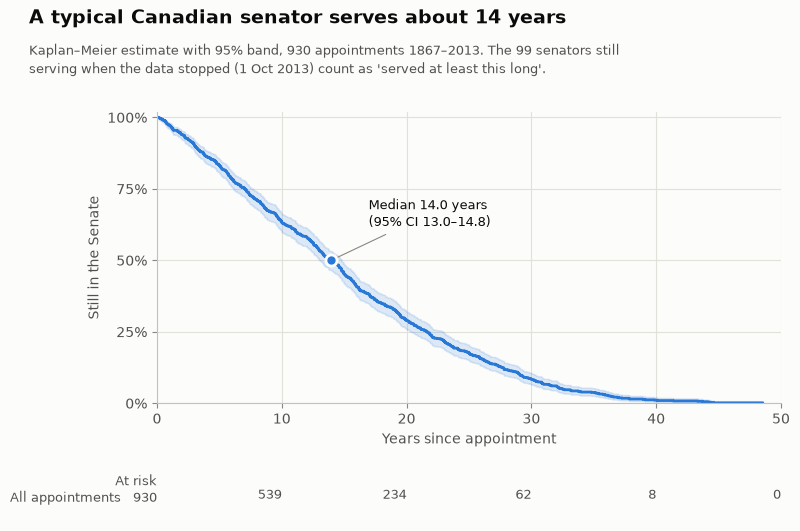

In [7]:
fig = plots.plot_km_overall(senators)

Half of all appointments lasted at least 14 years. The interval for the median is where the
95% band around the curve crosses 50%. The "at risk" row is how many senators were still being
watched at each point: by 40 years only 8 are left, so the right-hand end of the curve rests
on very few people.

## 3. Why censoring matters

Two common shortcuts:

1. **Completed terms only:** drop the 99 sitting senators and summarize the rest.
2. **Treat sitting senators as if they left on the data date:** keep them, but cut their
   terms off on 1 October 2013.

Both make terms look shorter. The first throws away exactly the people who are on track for
long terms (they're still going). The second counts unfinished terms as finished.

In [8]:
comparison = estimates.compare_methods({
    "All appointments": senators,
    prep.ERA_BEFORE: senators[~senators["after_1965_rule"]],
    prep.ERA_AFTER: senators[senators["after_1965_rule"]],
})
comparison.round(1)

,n,still_serving,pct_still_serving,completed_mean,completed_median,as_ended_mean,as_ended_median,km_median,km_lower,km_upper
group,,,,,,,,,,
All appointments,930,99,10.6,14.5,13.3,13.8,12.5,14.0,13.0,14.8
Appointed before June 1965,597,0,0.0,15.2,13.7,15.2,13.7,13.7,12.9,14.9
Appointed June 1965 or later,333,99,29.7,12.6,11.4,11.4,9.9,14.2,12.5,15.0


How to read this table:

- **Means vs medians.** Every average is above its median, even before 1965 when nothing is
  censored (15.2 vs 13.7): a few very long terms (up to 48.5 years) pull the average up. So
  the fair comparison is median against median.
- **Before June 1965, nobody is still serving**, and all three medians are identical (13.7).
  Kaplan–Meier isn't magic: with no censoring it *is* the ordinary median.
- **Since June 1965, 30% were still serving**, and the shortcuts give 11.4 and 9.9 years
  against Kaplan–Meier's 14.2. With the shortcuts, I would have "found" that the 1965 rule
  cut the typical term by two to four years. The Kaplan–Meier medians (13.7 before, 14.2
  after) show no such drop.

### A back-test: is Kaplan–Meier right, or just different?

I can check by going back in time. On 1 January 1990, 142 appointments had been made under
the retire-at-75 rule, and 86 of those senators were still serving. What would each method
have said that day, and what actually happened?

In [9]:
back = estimates.backtest(senators, cutoff="1990-01-01")
print(f"Cohort: {back['n']} appointments, {back['still_serving_at_cutoff']} still serving on 1 Jan 1990")
print(f"  completed terms only:     {back['completed_median']:.1f} years (mean {back['completed_mean']:.1f})")
print(f"  sitting treated as ended: {back['as_ended_median']:.1f} years (mean {back['as_ended_mean']:.1f})")
print(f"  Kaplan–Meier:             {back['km_median']:.1f} years (95% CI {back['km_lower']:.1f}–{back['km_upper']:.1f})")
print(f"What actually happened:     {back['eventual_median']:.1f} years")

Cohort: 142 appointments, 86 still serving on 1 Jan 1990
  completed terms only:     8.9 years (mean 9.6)
  sitting treated as ended: 10.2 years (mean 10.2)
  Kaplan–Meier:             15.8 years (95% CI 13.7–19.1)
What actually happened:     15.0 years


In [10]:
# The answer key: by 2013 only 3 of the 142 were still serving, and all three had already
# served far longer than the median, so the cohort's median term is known exactly.
cohort = senators[senators["after_1965_rule"] & (senators["start"] < "1990-01-01")]
cohort.loc[~cohort["observed"], ["name", "start", "years"]]

,name,start,years
186,"Cools, Anne C.",1984-01-13,29.72
351,"Watt, Charlie",1984-01-16,29.71
584,"Kenny, Colin",1984-06-29,29.26


In 1990 the shortcuts would have said 9–10 years. Kaplan–Meier said 15.8, with an interval
(13.7–19.1) that contains the answer we can now see: 15.0. The back-test leans on the one
assumption Kaplan–Meier always makes: senators still serving in 1990 would go on to leave at
the same rates as earlier senators who had served as long. Here, that held up.

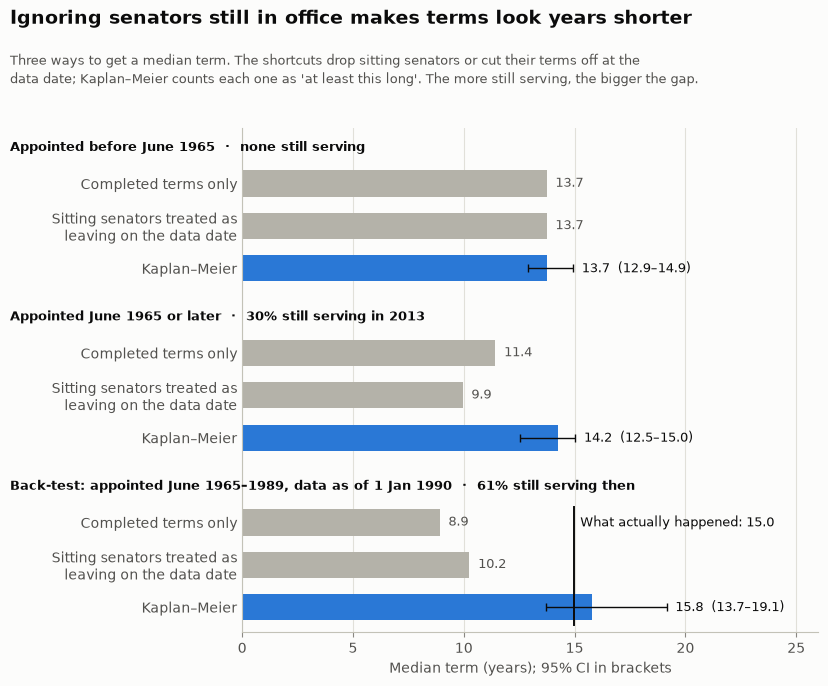

In [11]:
fig = plots.plot_naive_vs_km(comparison, back)

## 4. Did tenure change across eras?

The Constitution Act, 1965 (in force 2 June 1965) requires senators appointed after it to
retire at 75; senators appointed earlier kept their life appointments. The data has no ages,
so I can't model the rule itself (it caps a term at 75 minus age at appointment). What I can
do is compare appointments made before and after it.

In [12]:
before = senators[~senators["after_1965_rule"]]
after = senators[senators["after_1965_rule"]]
test = logrank_test(before["years"], after["years"], before["observed"], after["observed"])
print(f"Log-rank test, before vs after June 1965: chi2 = {test.test_statistic:.2f}, p = {test.p_value:.2f}")

milestones = [10, 20, 30, 35, 40]
still_serving = pd.DataFrame(
    {
        era: 100 * KaplanMeierFitter().fit(d["years"], d["observed"]).survival_function_at_times(milestones).to_numpy()
        for era, d in [(prep.ERA_BEFORE, before), (prep.ERA_AFTER, after)]
    },
    index=[f"after {t} years" for t in milestones],
).T
still_serving.round(1)  # % still in the Senate

Log-rank test, before vs after June 1965: chi2 = 1.15, p = 0.28


,after 10 years,after 20 years,after 30 years,after 35 years,after 40 years
Appointed before June 1965,62.6,30.2,8.5,4.5,1.3
Appointed June 1965 or later,65.1,25.5,8.1,0.7,0.0


The log-rank test compares the whole curves and finds no clear difference (p = 0.28). The
curves stay close for 30 years (8.5% vs 8.1% still serving), then split: 4.5% of senators
appointed before the rule were still in the Senate after 35 years, against 0.7% after it. The
longest term before the rule was 48.5 years; after it, 36.9. That is the shape an age cap would
produce, though a before/after comparison like this can't prove the rule caused it.

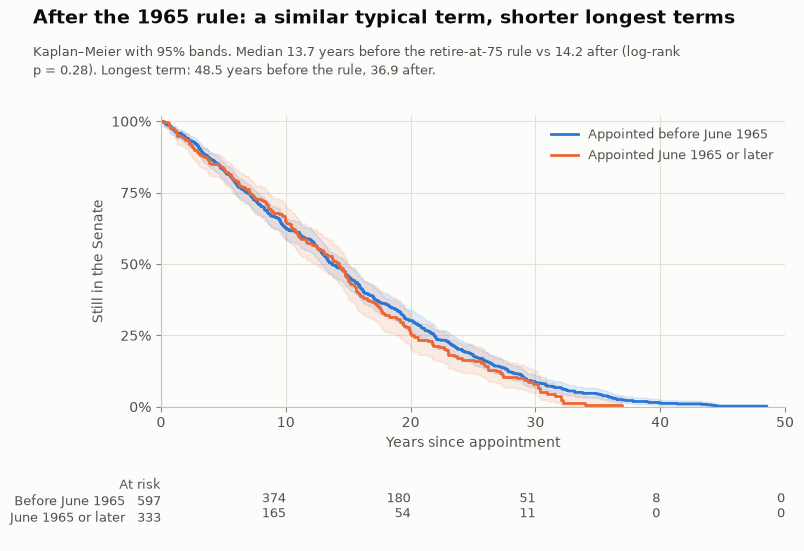

In [13]:
fig = plots.plot_km_by_era(senators)

### By 25-year period

The periods are roughly 25 years long, with one boundary exactly on 2 June 1965 so that no
period mixes the two rules.

In [14]:
test = multivariate_logrank_test(senators["years"], senators["period"], senators["observed"])
print(f"Log-rank test across the six periods: chi2 = {test.test_statistic:.2f} "
      f"on {test.degrees_of_freedom} df, p = {test.p_value:.2f}")
estimates.km_medians_by(senators, "period").round(1)

Log-rank test across the six periods: chi2 = 8.37 on 5 df, p = 0.14


,n,pct_still_serving,km_median,km_lower,km_upper
period,,,,,
1867–1889,169,0.0,12.5,9.5,15.8
1890–1914,132,0.0,13.2,11.1,15.2
1915–1939,143,0.0,14.6,12.1,16.4
1940–May 1965,153,0.0,14.2,12.9,16.2
June 1965–1989,142,2.1,15.0,13.4,16.9
1990–2013,191,50.3,11.6,9.9,14.9


Every period's median sits between 11.6 and 15.0 years, and the test finds no clear
difference (p = 0.14). The 1990–2013 median is the lowest but also the shakiest: half that
group was still serving, so the estimate leans on the senators appointed early in the period.

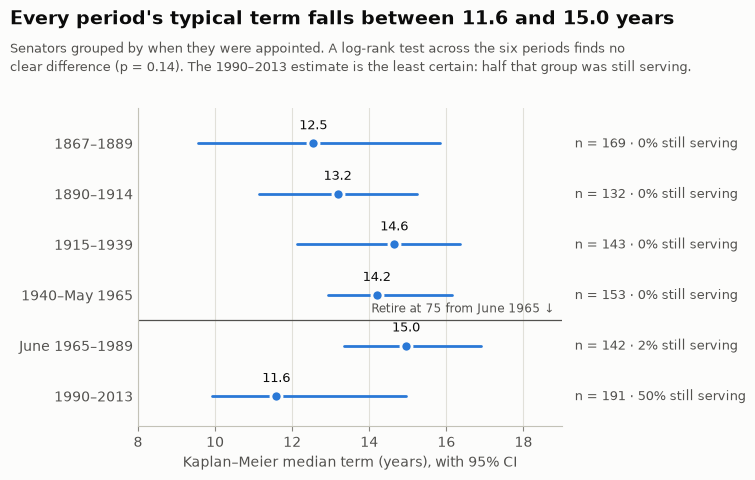

In [15]:
fig = plots.plot_median_by_period(senators)

## 5. A simple Cox model

A Cox proportional-hazards model looks at several factors at once. Its hazard ratio compares
how quickly two groups leave the Senate at any given point in a term: above 1 means leaving
sooner, below 1 means staying longer. I use three factors, each against a reference group:
era (vs appointed before June 1965), party family (vs Liberal) and region (vs Ontario).

In [16]:
design = estimates.cox_design(senators)
cph = estimates.fit_cox(design)
lr = cph.log_likelihood_ratio_test()
print(f"Concordance: {cph.concordance_index_:.2f}")
print(f"Likelihood-ratio test against a model with no factors: "
      f"chi2 = {lr.test_statistic:.2f} on {lr.degrees_freedom} df, p = {lr.p_value:.2f}")
estimates.hazard_ratio_table(cph).round(2)

Concordance: 0.53
Likelihood-ratio test against a model with no factors: chi2 = 5.10 on 6 df, p = 0.53


,hazard_ratio,lower_95,upper_95,p
covariate,,,,
appointed after 1965 rule,1.11,0.95,1.30,0.18
party: Conservative,1.02,0.88,1.17,0.83
party: Other,1.01,0.61,1.66,0.98
region: Atlantic,0.96,0.80,1.16,0.69
region: Quebec,1.04,0.86,1.25,0.71
region: West & North,0.85,0.69,1.04,0.12


Every interval includes 1, and the model as a whole does no better than a model with no
factors (p = 0.53). A concordance of 0.53 means that for a random pair of senators, the model
picks who leaves first barely more often than a coin flip would. Era, party and region say
very little about how long a particular senator will serve.

### Checking the proportional-hazards assumption

The model assumes each hazard ratio stays the same throughout a term. lifelines tests this with
the Schoenfeld residuals:

In [17]:
proportional_hazard_test(cph, design, time_transform="rank").summary[["test_statistic", "p"]].round(2)

,test_statistic,p
appointed after 1965 rule,1.72,0.19
party: Conservative,0.00,0.97
party: Other,5.17,0.02
region: Atlantic,0.76,0.38
region: Quebec,0.26,0.61
region: West & North,5.24,0.02


Two of the six coefficients are flagged at p ≈ 0.02: West & North, and the small "Other"
party group (17 appointments, with an interval from 0.61 to 1.66 anyway). With six tests, one or two
borderline results are not surprising, but the region one is worth checking. The standard fix
is to stratify: give each region its own baseline instead of a single hazard ratio, then
re-estimate the rest.

In [18]:
design_by_region = design.drop(columns=[c for c in design.columns if c.startswith("region:")])
design_by_region["region"] = senators["region"]
cph_by_region = estimates.fit_cox(design_by_region, strata=["region"])
estimates.hazard_ratio_table(cph_by_region).round(2)

,hazard_ratio,lower_95,upper_95,p
covariate,,,,
appointed after 1965 rule,1.10,0.94,1.29,0.22
party: Conservative,1.02,0.88,1.17,0.80
party: Other,1.02,0.61,1.68,0.95


In [19]:
proportional_hazard_test(cph_by_region, design_by_region, time_transform="rank").summary[["test_statistic", "p"]].round(2)

,test_statistic,p
appointed after 1965 rule,0.34,0.56
party: Conservative,0.06,0.81
party: Other,0.00,0.95


The era and party estimates barely move (era 1.11 to 1.10, Conservative 1.02 to 1.02) and
nothing is flagged any more, so the violation doesn't change the conclusion. The obvious
missing variable is **age at appointment**: under the age-75 rule it sets the longest possible
term, and this dataset doesn't have it.

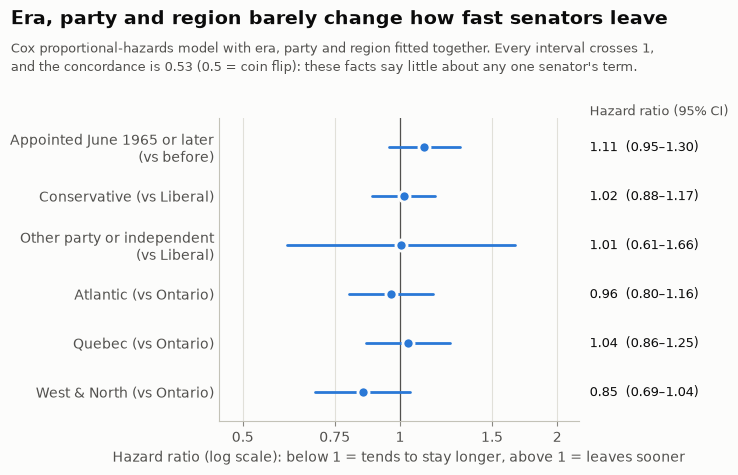

In [20]:
fig = plots.plot_cox_hazard_ratios(cph)

## 6. How senators leave

In [21]:
pd.crosstab(senators["period"], senators["reason"], margins=True, margins_name="All")

reason,Death,Resignation,Retirement,Still serving,All
period,,,,,
1867–1889,119,50,0,0,169
1890–1914,110,22,0,0,132
1915–1939,132,11,0,0,143
1940–May 1965,91,62,0,0,153
June 1965–1989,32,29,78,3,142
1990–2013,10,27,58,96,191
All,494,201,136,99,930


In [22]:
estimates.reason_shares(senators).round(0)  # % of each period's appointments

reason,Death,Resignation,Retirement,Still serving
period,,,,
1867–1889,70.0,30.0,0.0,0.0
1890–1914,83.0,17.0,0.0,0.0
1915–1939,92.0,8.0,0.0,0.0
1940–May 1965,59.0,41.0,0.0,0.0
June 1965–1989,23.0,20.0,55.0,2.0
1990–2013,5.0,14.0,30.0,50.0


Before June 1965, 76% of terms ended in death and the data records no retirements at all. For
senators appointed from June 1965 to 1989 (almost all of whom had left by 2013), retirement is
the most common exit (55%), with death at 23%.

One thing I can't explain from this data: resignations jump to 41% for senators appointed
between 1940 and May 1965.

In [23]:
resigned = senators[(senators["period"] == "1940–May 1965") & (senators["reason"] == "Resignation")]
print(f"{(resigned['end'] >= prep.RETIREMENT_RULE_DATE).sum()} of {len(resigned)} of these "
      "resignations happened after the 1965 rule came into force")

59 of 62 of these resignations happened after the 1965 rule came into force


Almost all of them came after 1965. The data doesn't say why, so I'm leaving it as an open
question rather than guessing.

**A note on competing risks.** Death, retirement and resignation compete with each other: a
senator who retires can no longer die in office. So I haven't fitted a separate Kaplan–Meier
curve for each reason (treating the other exits as censored would overstate each one); the
right tool for that is a cumulative incidence (Aalen–Johansen) estimate, which I'd add next.

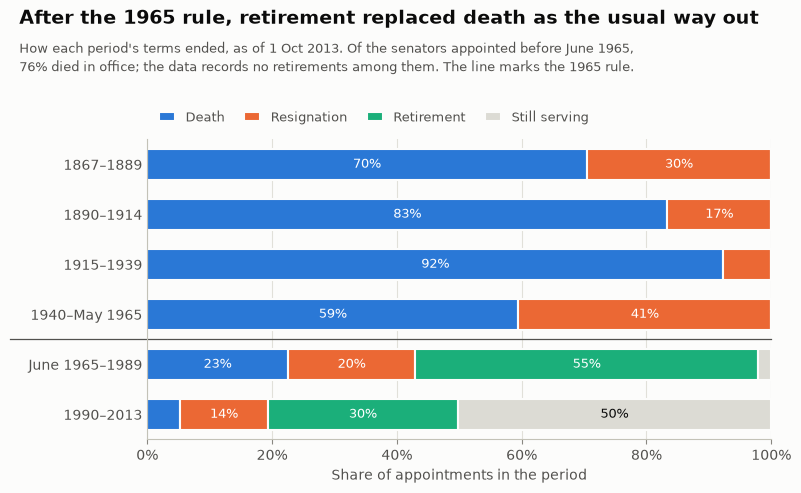

In [24]:
fig = plots.plot_reasons_by_period(senators)

## What this analysis can and can't say

- The data stops on 1 October 2013. Nothing after that date is included.
- There are no ages or birth dates, so the retire-at-75 rule can't be modelled directly.
- Rows are appointments, not people, and party is the affiliation at appointment.
- Kaplan–Meier and Cox assume that censoring is unrelated to how long someone would have
  served. Here censoring is purely a calendar cut-off, so the main risk is that recent
  appointees differ from earlier ones (for example, in age at appointment).
- lifelines doesn't document where the data came from, and I haven't checked it row by row
  against official Senate records.